# Contribution of the spatial features to the MuVI factors

Two reviewer comments ask the same question. The first says the spatial features explain only about 5 percent of factor variance. The second says Factors 2 and 6 look metabolic and compositional, and asks for an explicit account of what each feature class contributes.

This notebook makes the following argument:
1. The factors of the published model explain the spatial features much less than the other classes, and Factors 2 and 6 rest on metabolic, functional and compositional features.
2. The MISTy importances that encode space in the model barely correlate with each other or with the other classes, largely because they are sparse. A factor model explains a feature only through its covariances with other features, so it explains these poorly, and the low number is a technical property of the input. Section 9 derives this from the form of the model.
3. Removing the MISTy importances leaves the factors where they are.
4. Squidpy neighbourhood enrichment, a condensed spatial encoding whose features correlate, compresses much better, but cell type composition predicts a large part of it. COZI enrichment is as dense, yet its features correlate little, and it compresses only somewhat better than the MISTy importances.
5. Once composition is removed, no encoding gives factors that carry more spatial information than a model without any spatial feature. Better compression does not make the factors more spatial.

Making the factors more spatial is therefore a question for a different multifactorial design, for instance one that weights the feature classes or models the spatial features in their own views. This notebook does not attempt that.

The factors of the retained model in `MOFACell.ipynb` are the reference throughout. MuVI fits by stochastic variational inference from a random start, so a refit moves the factors even when the input does not change. Refits with other seeds on the published input give the yardstick. A change of input matters only if it moves the factors further than a change of seed.

The notebook runs in the `liana-squidpy` environment, a clone of `liana` with squidpy added. Squidpy raises numpy from 1.26.4 to 2.0.2. It also pulls zarr 3, which breaks `anndata` 0.11.2, so zarr stays below 3. Section 2 checks that the reference fit still reproduces the published scores with these versions. `environments/README.md` describes how to create the environment, and `environments/scverse_squidpy.yml` lists its versions.

## Setup

In [1]:
import logging
import os
import re
import time
import numpy as np
import pandas as pd
import anndata as ad
import muon as mu
import muvi
import squidpy as sq
import torch
from plotnine import *
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

logging.getLogger("muvi").setLevel(logging.WARNING)

data_dir = "../../data/"
output_dir = data_dir + "spatial_features/"
figure_dir = "../../figures/spatial_features/"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

n_factors = 10                  # the retained model of MOFACell.ipynb
reference_seed = 0              # the seed that reproduces data/factor_scores.csv
comparison_seeds = [1, 2, 3, 4, 5, 6, 7, 8]
n_permutations = 200            # permutations behind each squidpy enrichment z-score
split_seed = 0                  # cross-validation folds and squidpy permutations
ridge_alphas = np.logspace(-2, 4, 13)
cache_path = output_dir + "refits.pkl"
squidpy_path = output_dir + "squidpy_nhood_enrichment.csv"

# Blues as in the R2 plots of MOFACell.ipynb; the feature sets keep the blue ramp of the project,
# with orange for the model without spatial features
def scale_fill_r2(name=""):
    return scale_fill_cmap(cmap_name="Blues", name=name)

set_colors = {"MISTy, all features": "#08306b", "MISTy, juxtaview features": "#2171b5", "MISTy, own-type and cancer neighbours": "#6baed6",
              "COZI enrichment": "#7570b3", "Squidpy enrichment": "#1b9e77", "No spatial": "#d95f0e"}

/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


## 1. Feature classes
The MuVI input holds one view per cell type. Within a view, each feature describes that cell type across the cores. The classes follow how `PrepareMuData.ipynb` built the features.

| Class | What a feature measures |
|---|---|
| Composition | The fraction of all cells of the core that belong to the cell type |
| Metabolism | The median of a metabolic marker in the cell type |
| Functional | The median of PDL1, STING1, MSH2 or MSH6 in the cell type |
| Morphology | The mean and standard deviation of the area, perimeter and eccentricity of the cell type |
| MISTy juxtaview | A MISTy importance at 40 pixels, about 16 µm, which covers cells in contact |
| MISTy paraview | A MISTy importance at 120 pixels, about 47 µm, which covers the wider neighbourhood |

A MISTy importance says how much the abundance of one cell type around a cell helps predict the cell type of interest. These two classes are the only place where cell positions enter the published model. Section 4 adds two more spatial classes.

In [2]:
features = mu.read_h5mu(data_dir + "celltype_features_with_functional_markers.h5mu")
view_names = list(features.mod.keys())
factor_order = [f"Factor {i}" for i in range(1, n_factors + 1)]

def feature_class(name):
    if name.startswith("cozi"):
        return "COZI enrichment"
    if name.startswith("squidpy"):
        return "Squidpy enrichment"
    if name.startswith("juxtaview"):
        return "MISTy juxtaview"
    if name.startswith("paraview"):
        return "MISTy paraview"
    if name == "proportion":
        return "Composition"
    if re.search(r"(eccentricity|perimeter|area)", name):
        return "Morphology"
    if name in ["PDL1", "STING1", "MSH2", "MSH6"]:
        return "Functional"
    return "Metabolism"

class_order = ["Composition", "Metabolism", "Functional", "Morphology",
               "MISTy juxtaview", "MISTy paraview", "COZI enrichment", "Squidpy enrichment"]
spatial_classes = ["MISTy juxtaview", "MISTy paraview", "COZI enrichment", "Squidpy enrichment"]
published_classes = class_order[:6]

feature_table = pd.DataFrame([{"view": v, "feature": n, "class": feature_class(n)}
                              for v in view_names for n in features.mod[v].var_names])
feature_table["class"] = pd.Categorical(feature_table["class"], categories=class_order)
counts = feature_table.groupby("class", observed=True).size().rename("features").to_frame()
counts["share of the input"] = (counts.features / len(feature_table)).map("{:.0%}".format)
counts

/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


,features,share of the input
class,,
Composition,8,3%
Metabolism,122,40%
Functional,30,10%
Morphology,48,16%
MISTy juxtaview,43,14%
MISTy paraview,57,19%


## 2. The reference model
The retained model of `MOFACell.ipynb` has 10 factors and no non-negativity, and it was fit with seed 0 on the GPU. Nobody saved the model, so the notebook refits it and checks the scores against `data/factor_scores.csv`.

In [3]:
def standardise(X):
    '''Centre and scale each feature, ignoring missing values, as in MOFACell.ipynb'''
    X = X - np.nanmean(X, axis=0, keepdims=True)
    return X / np.nanstd(X, axis=0)

device = f"cuda:{muvi.get_free_gpu_idx()}"

def fit_model(views, seed):
    '''Fit MuVI on a view to data frame mapping, with the preprocessing of MOFACell.ipynb'''
    modalities = {}
    for view, frame in views.items():
        adata = ad.AnnData(standardise(frame.values.astype(np.float64)))
        adata.obs_names, adata.var_names = frame.index, frame.columns
        modalities[view] = adata
    model = muvi.tl.from_mdata(mu.MuData(modalities), n_factors=n_factors, nmf=False, device=device)
    model.fit(seed=seed, verbose=False)
    return model

published_features = {v: features.mod[v].to_df() for v in view_names}
reference_model = fit_model(published_features, reference_seed)

internal_names = [f"factor_{i}" for i in range(n_factors)]
reference_scores = reference_model.get_factor_scores(as_df=True)[internal_names]
reference_scores.columns = factor_order
reference_scores.index = features.obs_names
exported = pd.read_csv(data_dir + "factor_scores.csv")[factor_order]
assert np.allclose(reference_scores.values, exported.values, atol=1e-5), "the refit does not reproduce MOFACell.ipynb"
print("numpy", np.__version__, "| largest difference to the exported scores:",
      np.abs(reference_scores.values - exported.values).max())

2026-10-21 12:00:29,049 - muvi.core.models - WARNING - No view names provided!


2026-10-21 12:00:29,052 - muvi.core.models - WARNING - No prior feature sets provided, running model uninformed.


/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


2026-10-21 12:00:29,350 - root - INFO - Guessed max_plate_nesting = 3


Relative improvement of -0.0007554 < 1e-05 for 10 step(s) in a row, stopping early.
numpy 2.0.2 | largest difference to the exported scores: 4.440892098500626e-16


## 3. What each factor explains, by feature class
For one factor and one set of features, the variance explained is `1 - SS(residual) / SS(observed)`. The residual is what that single factor fails to reconstruct. MuVI uses the same definition, and here it runs on the features of one class at a time. The observations are centred and scaled, as the model sees them. Every feature therefore carries the same total variance, and differences between classes do not come from scale.

In [4]:
def variance_explained(model):
    '''Variance explained per factor and feature class, and by all factors together'''
    scores = model.get_factor_scores(as_df=True)[internal_names].values
    loadings = model.get_factor_loadings(as_df=True)
    observations = model.get_observations(as_df=True)
    residual_sum, total_sum = {}, {}
    for view in view_names:
        y = observations[view].values
        w = loadings[view].loc[internal_names].values
        classes = pd.Series([feature_class(n) for n in observations[view].columns])
        for cls, columns in classes.groupby(classes).groups.items():
            index = np.asarray(columns)
            total_sum[cls] = total_sum.get(cls, 0) + np.nansum(y[:, index] ** 2)
            for k in range(n_factors):
                prediction = np.outer(scores[:, k], w[k, index])
                residual_sum[(cls, k)] = residual_sum.get((cls, k), 0) + np.nansum((y[:, index] - prediction) ** 2)
            prediction = scores @ w[:, index]
            residual_sum[(cls, "all")] = residual_sum.get((cls, "all"), 0) + np.nansum((y[:, index] - prediction) ** 2)
    present = [c for c in class_order if c in total_sum]
    per_factor = pd.DataFrame({factor_order[k]: {c: 1 - residual_sum[(c, k)] / total_sum[c] for c in present}
                               for k in range(n_factors)}).reindex(present)
    all_factors = pd.Series({c: 1 - residual_sum[(c, "all")] / total_sum[c] for c in present})
    return per_factor, all_factors

reference_r2, reference_r2_all = variance_explained(reference_model)
muvi_r2 = np.mean(list(muvi.tl.variance_explained(reference_model)[0].values()))
print(f"check against MuVI, mean variance explained over the views: {muvi_r2:.3f}")
(reference_r2_all * 100).round(1).rename("variance explained by the 10 factors (%)").to_frame()

2026-10-21 12:01:12,286 - muvi.tools.utils - WARNING - Cache has not yet been setup, initialising model cache.


check against MuVI, mean variance explained over the views: 0.400


/home/loan/miniforge3/envs/liana-squidpy/lib/python3.11/site-packages/anndata/_core/anndata.py:401: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.


,variance explained by the 10 factors (%)
Composition,31.5
Metabolism,67.2
Functional,57.8
Morphology,27.1
MISTy juxtaview,10.8
MISTy paraview,4.5


The 10 factors explain the two MISTy classes much less than any other class. The MISTy paraview class is the source of the 5 percent in the first comment, and the MISTy juxtaview class sits higher. Reporting the two apart is more accurate than one pooled figure. The heatmap splits the same quantity by factor.

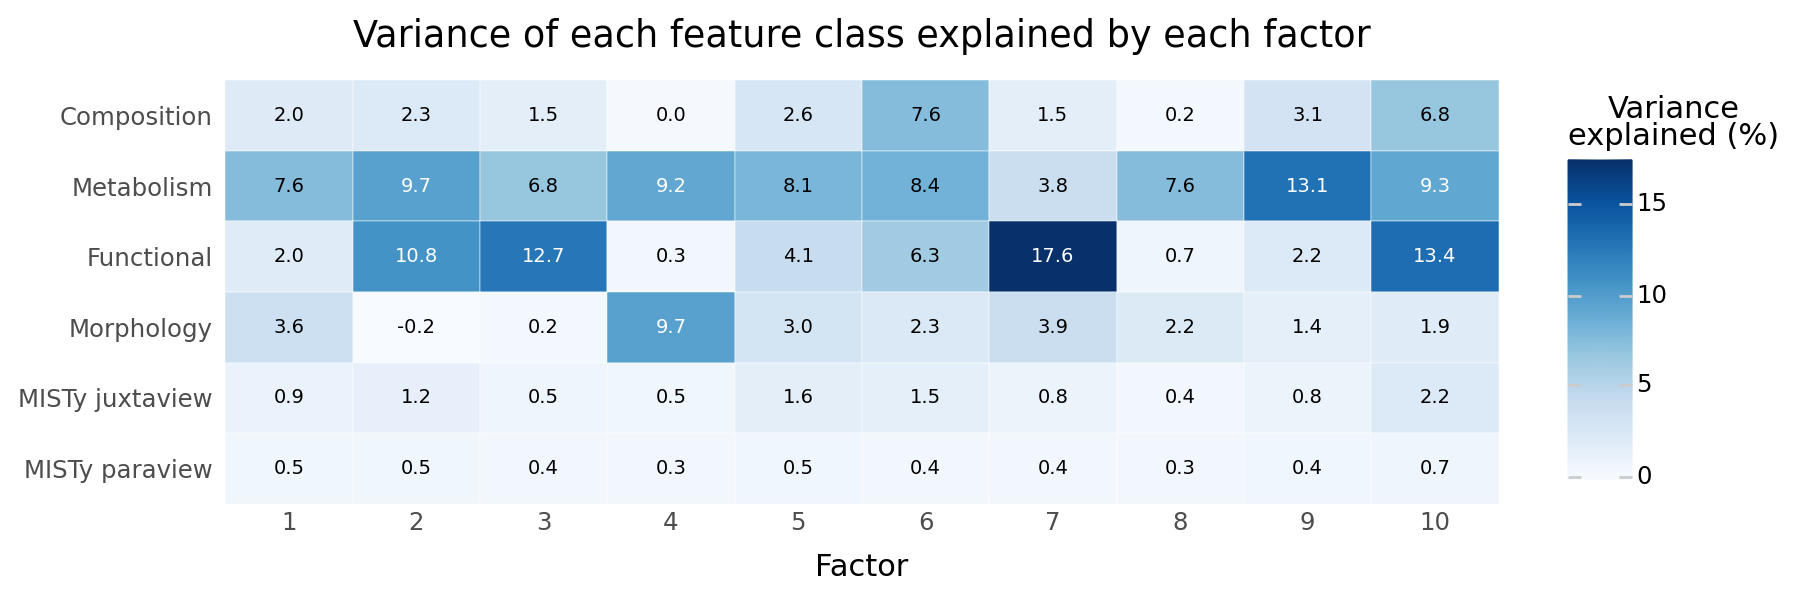

In [5]:
r2_long = (reference_r2 * 100).rename_axis("class").reset_index().melt(id_vars="class", var_name="factor", value_name="r2")
r2_long["class"] = pd.Categorical(r2_long["class"], categories=published_classes[::-1])
r2_long["factor"] = pd.Categorical(r2_long.factor.str.replace("Factor ", ""), categories=[str(i) for i in range(1, 11)])

gp = (ggplot(r2_long, aes(x="factor", y="class", fill="r2"))
      + geom_tile(color="white")
      + geom_text(aes(label="r2", color="r2 > 9"), format_string="{:.1f}", size=7, show_legend=False)
      + scale_color_manual(values={True: "white", False: "black"})
      + scale_fill_r2("Variance\nexplained (%)")
      + labs(x="Factor", y="", title="Variance of each feature class explained by each factor")
      + theme_classic()
      + theme(figure_size=(9, 3), axis_line=element_blank(), axis_ticks=element_blank()))
gp.save(figure_dir + "variance_explained_by_class.pdf", verbose=False)
gp

The second comment asks what each factor is made of. For each factor, the squared loadings are summed over the features of a class and divided by the factor's total. The result is the share of the factor that sits on each class.

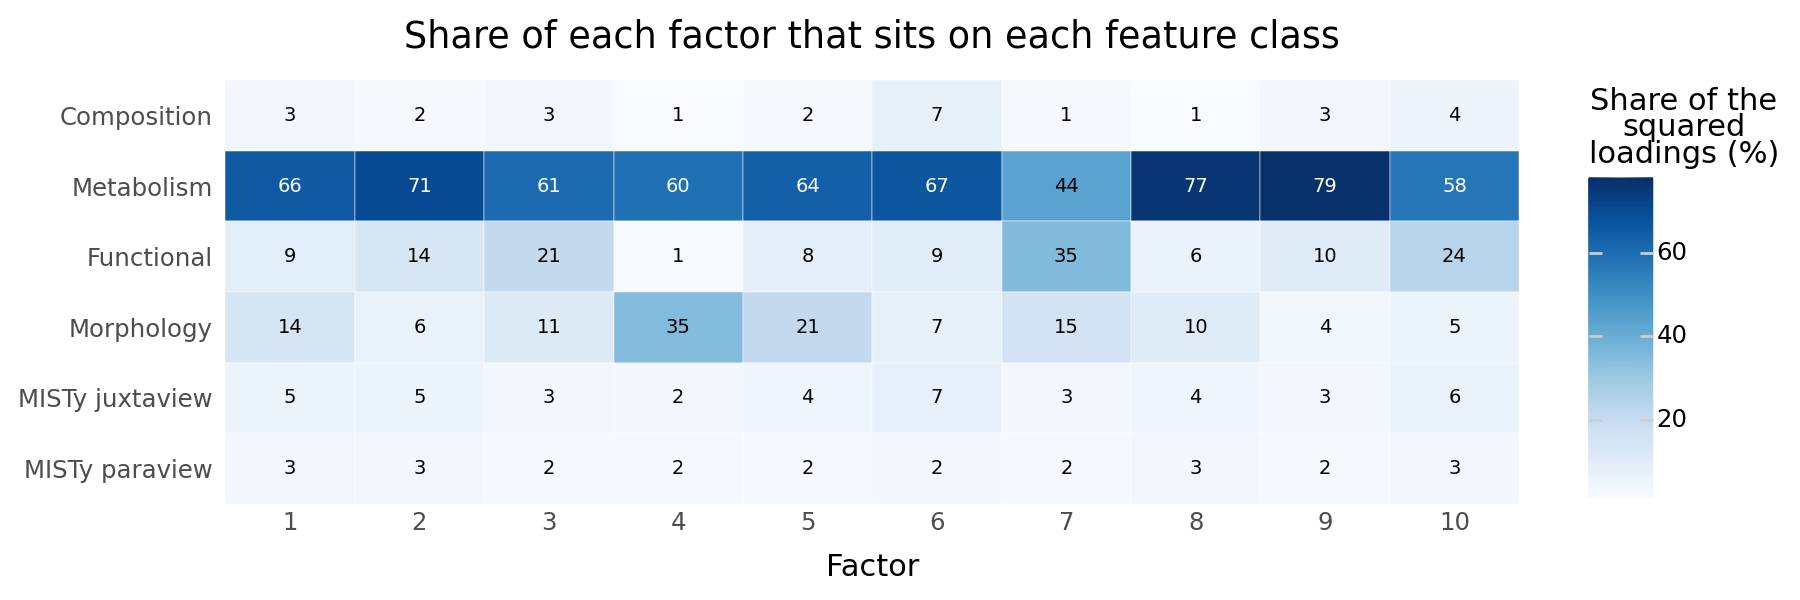

In [6]:
loading_table = pd.concat({v: reference_model.get_factor_loadings(as_df=True)[v].loc[internal_names].T
                           for v in view_names}, names=["view", "feature"])
loading_table.columns = factor_order
loading_table["class"] = [feature_class(f) for _, f in loading_table.index]
squared = loading_table.groupby("class", observed=True)[factor_order].apply(lambda d: (d ** 2).sum())
share = (squared / squared.sum()).reindex(published_classes)

share_long = (share * 100).rename_axis("class").reset_index().melt(id_vars="class", var_name="factor", value_name="percent")
share_long["class"] = pd.Categorical(share_long["class"], categories=published_classes[::-1])
share_long["factor"] = pd.Categorical(share_long.factor.str.replace("Factor ", ""), categories=[str(i) for i in range(1, 11)])

gp = (ggplot(share_long, aes(x="factor", y="class", fill="percent"))
      + geom_tile(color="white")
      + geom_text(aes(label="percent", color="percent > 45"), format_string="{:.0f}", size=7, show_legend=False)
      + scale_color_manual(values={True: "white", False: "black"})
      + scale_fill_r2("Share of the\nsquared\nloadings (%)")
      + labs(x="Factor", y="", title="Share of each factor that sits on each feature class")
      + theme_classic()
      + theme(figure_size=(9, 3), axis_line=element_blank(), axis_ticks=element_blank()))
gp.save(figure_dir + "loading_share_by_class.pdf", verbose=False)
gp

Metabolism holds the largest share of every factor, but it also holds the most features. The table divides each share by the class's share of the features. A value of 1 means the class carries exactly its weight in features.

In [7]:
share.div((counts.features / counts.features.sum()).reindex(published_classes), axis=0).round(2)

,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10
class,,,,,,,,,,
Composition,1.21,0.62,0.99,0.27,0.62,2.78,0.51,0.21,1.18,1.72
Metabolism,1.67,1.79,1.54,1.50,1.63,1.70,1.11,1.94,1.99,1.46
Functional,0.94,1.39,2.14,0.09,0.79,0.96,3.64,0.58,1.01,2.45
Morphology,0.87,0.39,0.71,2.26,1.33,0.43,0.96,0.63,0.23,0.33
MISTy juxtaview,0.37,0.36,0.20,0.15,0.28,0.50,0.20,0.30,0.22,0.42
MISTy paraview,0.14,0.14,0.09,0.09,0.09,0.12,0.08,0.15,0.10,0.14


Factors 2 and 6 put most of their weight on metabolism and the functional markers, and Factor 6 has the largest compositional share of all factors. After the correction for class size, the two MISTy classes stay below their weight in features for every factor. The reviewer's reading of Factors 2 and 6 is correct.

## 4. Spatial encodings to compare
Six feature sets differ only in how cell positions enter the model. Every non-spatial feature stays in all six.

| Feature set | Spatial features it keeps |
|---|---|
| MISTy, all features | The 100 MISTy importances of the published model |
| MISTy, juxtaview features | The 43 MISTy importances at contact range, 40 pixels |
| MISTy, own-type and cancer neighbours | The MISTy importances in which the neighbouring cell type is either the target cell type itself, which measures how clustered that cell type is, or cancer cells, which measures how close it sits to the epithelium |
| COZI enrichment | The COZI scores of `spatial/CellTypeCOZI.ipynb` instead of any MISTy importance |
| Squidpy enrichment | The squidpy neighbourhood enrichment z-scores instead of any MISTy importance |
| No spatial | None |

The COZI scores come from `spatial/CellTypeCOZI.ipynb`, which computes them from the cell table with the COZI fork of scimap and writes `data/cozi_celltypes.csv`. Like MISTy, which models a cell type in a core whenever it is present there, COZI keeps every cell type, however rare. An earlier file, `data/cozi_all_fovs.csv`, gave strongly negative scores to weakly supported pairs and is no longer used. `CellTypeCOZI.ipynb` compares the two.

A COZI score says how much more often one cell type sits next to another than a null model expects. The scores are directed, so the enrichment of B around A differs from that of A around B. The squidpy z-scores come from `squidpy.gr.nhood_enrichment`, on a Delaunay graph of the cells of each core from `squidpy.gr.spatial_neighbors`. The z-score compares the number of edges between two classes with a permutation of the labels. It is symmetric.

The COZI scores cover the 14 annotated cell types, while each MuVI view is one of 8 coarser classes. Each coarse pair therefore takes the mean of the fine pairs it contains, and the pairs that involve `Unclear` cells drop out. The squidpy scores use the coarse classes directly. Both encodings give each view one feature per coarse class, including itself, so 8 per view. Where a cell type is absent from a core, COZI gives no score and the squidpy z-score is infinite or undefined. Both become missing values, which MuVI already handles in the published input.

In [8]:
cell_types = ["CD163_Macrophage", "CD68_Macrophage", "Other_immune_cell", "Endothelial_cell", "Cancer_cell",
              "CD4_Tcell", "CD8_Tcell", "NK_cell", "Monocyte", "Neutrophil", "APC", "CAF", "B_cell", "T_reg_cell"]

def target_and_predictor(name):
    '''Split <prefix>.<target>_<neighbour>, where both cell types may contain underscores'''
    pair = name.split(".")[-1]
    for target in sorted(cell_types, key=len, reverse=True):
        if pair.startswith(target + "_"):
            return target, pair[len(target) + 1:]
    return pair, ""  # a pair with a cell type that no view covers, such as Unclear

spatial = feature_table[feature_table["class"].isin(spatial_classes)].copy()
spatial[["target", "predictor"]] = [target_and_predictor(n) for n in spatial.feature]
assert (spatial.predictor != "").all(), "a MISTy feature could not be split into two cell types"
spatial["compact"] = (spatial.target == spatial.predictor) | (spatial.predictor == "Cancer_cell")
compact_spatial = set(zip(spatial.loc[spatial.compact, "view"], spatial.loc[spatial.compact, "feature"]))

def keep_misty(view, name, policy):
    if policy == "all":
        return True
    if policy == "juxtaview":
        return feature_class(name) == "MISTy juxtaview"
    if policy == "self and cancer":
        return (view, name) in compact_spatial
    return False

coarse_of = {fine: coarse for coarse, fines in {
    "Other_immune_cell": ["APC", "B_cell", "Neutrophil", "Other_immune_cell"],
    "Fibroblast": ["CAF"],
    "Macrophage": ["CD163_Macrophage", "CD68_Macrophage"],
    "CD4_lymphocyte": ["CD4_Tcell", "T_reg_cell"],
    "Epithelial_cell": ["Cancer_cell"],
    "Endothelial_cell": ["Endothelial_cell"],
    "Monocyte": ["Monocyte"],
    "Cytotoxic_lymphocyte": ["NK_cell", "CD8_Tcell"],
}.items() for fine in fines}

# COZI scores, from the annotated cell types to the coarse classes of the views
cozi = pd.read_csv(data_dir + "cozi_celltypes.csv", index_col="fov")[["interaction", "zscore"]]
cozi.columns = ["interaction", "value"]
cozi[["target", "neighbour"]] = [target_and_predictor("." + i) for i in cozi.interaction]
cozi = cozi[cozi.target.isin(coarse_of) & cozi.neighbour.isin(coarse_of)]
cozi["view"] = cozi.target.map(coarse_of)
cozi["feature"] = "cozi." + cozi.neighbour.map(coarse_of)
cozi_features = {v: (frame.pivot_table(index=frame.index, columns="feature", values="value", aggfunc="mean")
                     .reindex(features.obs_names))
                 for v, frame in cozi.groupby("view")}

# Squidpy neighbourhood enrichment, computed once per core and cached
if os.path.exists(squidpy_path):
    squidpy_long = pd.read_csv(squidpy_path)
else:
    positions = pd.read_csv(data_dir + "cell_table_with_types_stage.csv", low_memory=False,
                            usecols=["fov", "annotation_consensus", "centroid-0", "centroid-1"])
    positions = positions[positions.fov.isin(features.obs_names)]
    positions["view"] = positions.annotation_consensus.map(coarse_of)
    positions = positions.dropna(subset=["view"])
    rows = []
    for fov, core in positions.groupby("fov"):
        adata = ad.AnnData(np.zeros((len(core), 1), dtype=np.float32),
                           obs=pd.DataFrame({"view": pd.Categorical(core.view.values, categories=view_names)},
                                            index=core.index.astype(str)))
        adata.obsm["spatial"] = core[["centroid-0", "centroid-1"]].values
        sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)
        sq.gr.nhood_enrichment(adata, cluster_key="view", seed=split_seed, n_perms=n_permutations,
                               show_progress_bar=False)
        zscore = adata.uns["view_nhood_enrichment"]["zscore"]
        rows += [{"fov": fov, "view": a, "neighbour": b, "zscore": zscore[i, j]}
                 for i, a in enumerate(view_names) for j, b in enumerate(view_names)]
    squidpy_long = pd.DataFrame(rows)
    squidpy_long.to_csv(squidpy_path, index=False)
squidpy_long["zscore"] = squidpy_long.zscore.replace([np.inf, -np.inf], np.nan)
squidpy_long["feature"] = "squidpy." + squidpy_long.neighbour
squidpy_features = {v: frame.pivot_table(index="fov", columns="feature", values="zscore").reindex(features.obs_names)
                    for v, frame in squidpy_long.groupby("view")}

def build_feature_set(policy):
    '''One data frame per view: the non-spatial features, plus the spatial encoding of the policy'''
    out = {}
    for view in view_names:
        frame = published_features[view]
        kept = [c for c in frame.columns
                if feature_class(c) not in spatial_classes or keep_misty(view, c, policy)]
        out[view] = frame[kept]
        if policy == "cozi":
            out[view] = pd.concat([out[view], cozi_features[view]], axis=1)
        if policy == "squidpy":
            out[view] = pd.concat([out[view], squidpy_features[view]], axis=1)
    return out

def spatial_block(views):
    '''The spatial features of a feature set, all views side by side'''
    return pd.concat([frame[[c for c in frame.columns if feature_class(c) in spatial_classes]]
                      for frame in views.values()], axis=1)

feature_sets = {label: build_feature_set(policy) for label, policy in [
    ("MISTy, all features", "all"), ("MISTy, juxtaview features", "juxtaview"), ("MISTy, own-type and cancer neighbours", "self and cancer"),
    ("COZI enrichment", "cozi"), ("Squidpy enrichment", "squidpy"), ("No spatial", "none")]}
pd.DataFrame({label: {"features": sum(f.shape[1] for f in views.values()),
                      "spatial features": spatial_block(views).shape[1],
                      "missing spatial values": int(spatial_block(views).isna().sum().sum())}
              for label, views in feature_sets.items()}).T

,features,spatial features,missing spatial values
"MISTy, all features",308,100,0
"MISTy, juxtaview features",251,43,0
"MISTy, own-type and cancer neighbours",239,31,0
COZI enrichment,272,64,1187
Squidpy enrichment,272,64,1259
No spatial,208,0,0


## 5. How compressible each spatial encoding is
A model with 10 factors reconstructs a block of features well when the block has low-rank structure, meaning that a few directions describe most of it. The measures below describe each spatial block on its own, before any model is fit. Missing values are set to the feature mean, which is zero after scaling.

| Measure | What it measures |
|---|---|
| Exact zeros | The share of values that are exactly 0 before scaling |
| Mean absolute correlation | How strongly the features of the block correlate with each other, averaged over all pairs |
| Predictable from the other classes | The share of the block's variance that the non-spatial features predict, in ridge regression with five-fold cross-validation |
| Reach of 10 components | The share of the block's variance in its first 10 principal components. No model with 10 factors can explain more |

In [9]:
def zero_filled(frame):
    '''Scaled as the model sees it, with missing values at the feature mean'''
    return np.nan_to_num(standardise(frame.values.astype(np.float64)))

def cross_validated_r2(predictors, targets):
    '''Share of the variance of the targets predicted by ridge regression, over five folds'''
    residual_sum, total_sum = 0.0, 0.0
    for train, test in KFold(5, shuffle=True, random_state=split_seed).split(predictors):
        fitted = RidgeCV(alphas=ridge_alphas).fit(predictors[train], targets[train])
        residual_sum += ((targets[test] - fitted.predict(predictors[test])) ** 2).sum()
        total_sum += ((targets[test] - targets[train].mean(axis=0)) ** 2).sum()
    return 1 - residual_sum / total_sum

def top_components(matrix, k=n_factors):
    '''Share of the variance in the first k principal components'''
    singular = np.linalg.svd(matrix - matrix.mean(axis=0), compute_uv=False)
    return (singular[:k] ** 2).sum() / (singular ** 2).sum()

non_spatial = zero_filled(pd.concat([frame[[c for c in frame.columns if feature_class(c) not in spatial_classes]]
                                     for frame in published_features.values()], axis=1))
encodings = [label for label in feature_sets if label != "No spatial"]
properties = []
for label in encodings:
    raw = spatial_block(feature_sets[label])
    block = zero_filled(raw)
    correlation = np.corrcoef(block, rowvar=False)
    properties.append({
        "feature set": label,
        "Exact zeros": float((raw.values == 0).sum() / raw.notna().values.sum()),
        "Mean absolute correlation": np.nanmean(np.abs(correlation[~np.eye(len(correlation), dtype=bool)])),
        "Predictable from the other classes": cross_validated_r2(non_spatial, block),
        "Reach of 10 components": top_components(block),
    })
properties = pd.DataFrame(properties).set_index("feature set")
properties.round(3)

,Exact zeros,Mean absolute correlation,Predictable from the other classes,Reach of 10 components
feature set,,,,
"MISTy, all features",0.762,0.051,0.028,0.251
"MISTy, juxtaview features",0.701,0.069,0.074,0.423
"MISTy, own-type and cancer neighbours",0.580,0.071,0.073,0.529
COZI enrichment,0.000,0.079,0.078,0.425
Squidpy enrichment,0.000,0.201,0.224,0.680


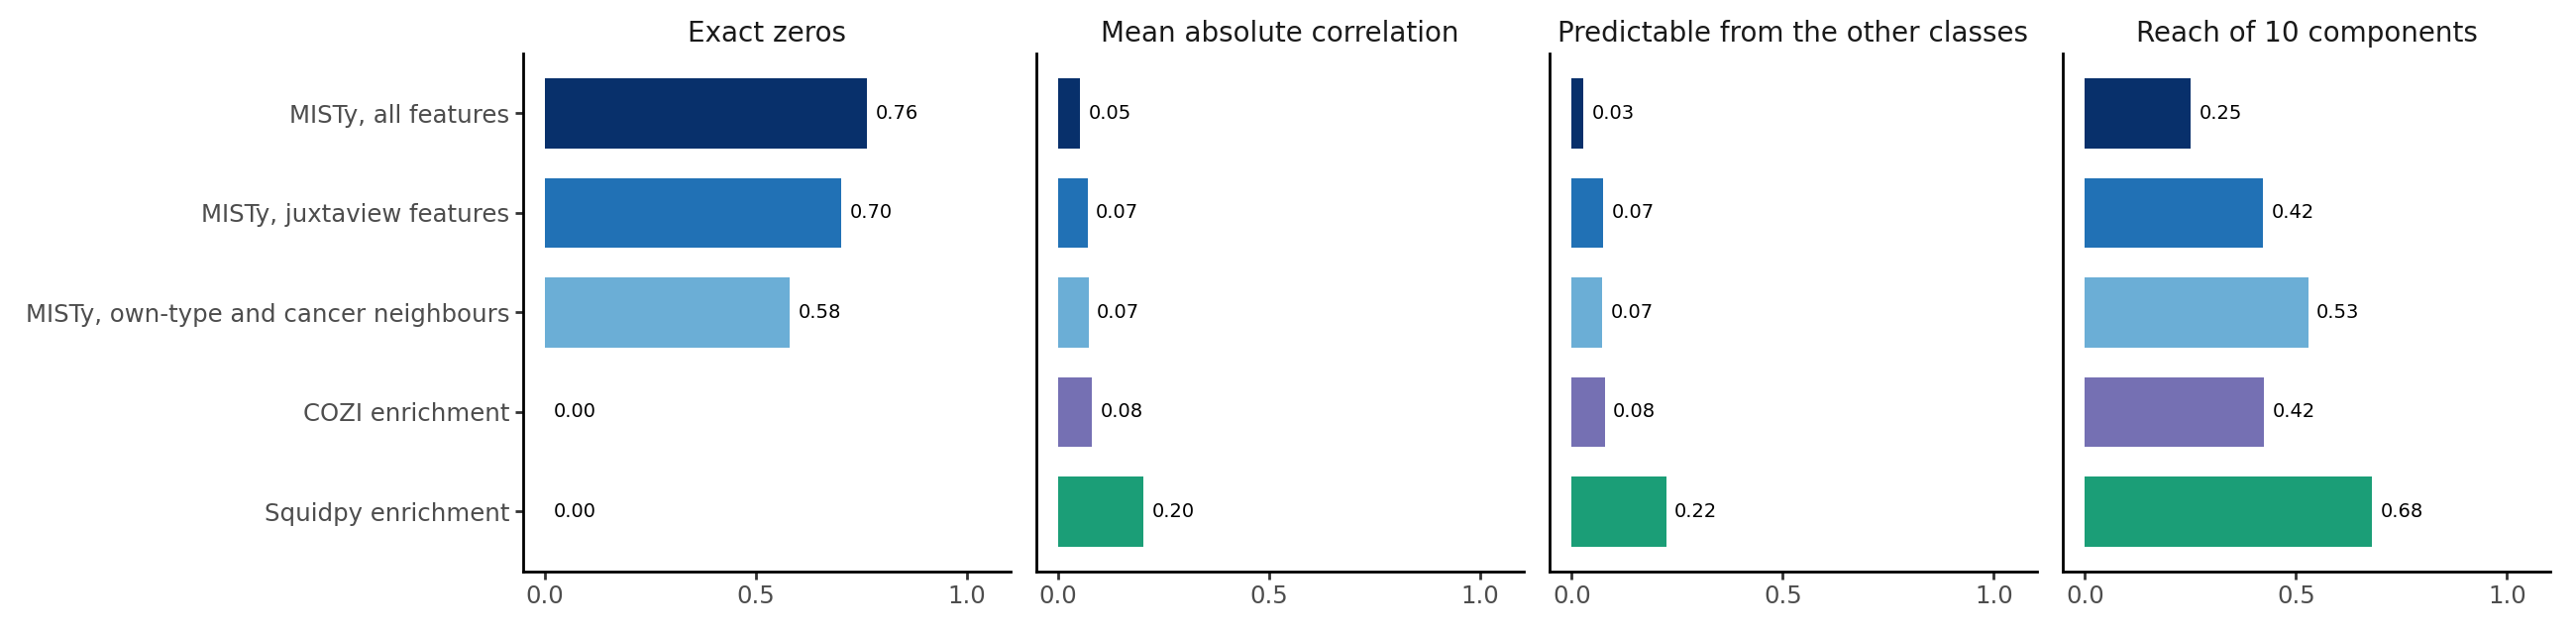

In [10]:
property_long = properties.rename_axis("feature set").reset_index().melt(
    id_vars="feature set", var_name="measure", value_name="value")
property_long["measure"] = pd.Categorical(property_long.measure, categories=list(properties.columns))
property_long["feature set"] = pd.Categorical(property_long["feature set"], categories=encodings[::-1])

gp = (ggplot(property_long, aes(x="feature set", y="value", fill="feature set"))
      + geom_col(width=0.7)
      + geom_text(aes(label="value"), format_string="{:.2f}", ha="left", size=7, nudge_y=0.02)
      + coord_flip()
      + facet_wrap("~measure", ncol=4)
      + scale_fill_manual(values=set_colors, guide=None)
      + scale_y_continuous(limits=(0, 1.05), breaks=[0, 0.5, 1])
      + labs(x="", y="")
      + theme_classic()
      + theme(figure_size=(13, 3.2), strip_background=element_blank(), strip_text=element_text(size=10)))
gp.save(figure_dir + "spatial_encoding_properties.pdf", verbose=False)
gp

Most MISTy values are exactly zero, because MISTy keeps an importance only where a neighbouring cell type helps the prediction. The nonzero values rarely coincide between features, so the importances barely correlate with each other or with the other classes. Their variance spreads over many directions, and a 10-factor model reaches little of it. Section 9 shows from the form of the model that the correlations decide how much the factors explain, and that sparsity matters because it keeps them low. This is why the published model explains so little of the spatial features. It is a property of how MISTy encodes space, and it does not show that the tissue lacks spatial structure.

The two enrichment encodings are dense, but they differ in everything else. The squidpy z-scores correlate with each other, and the other classes predict a larger share of them, so a 10-factor model can reach much more of them. The COZI scores correlate barely more than the MISTy importances, and the other classes predict no more of them, so a 10-factor model reaches about as much of them as of the MISTy subsets. Density alone does not make an encoding compressible.

## 6. Refits with each encoding
Each feature set is fit with the reference seed and the eight comparison seeds, and the fits are cached. The set MISTy, all features is the published input, so its refits differ from the reference only by the seed. They give the baseline.

In [11]:
refits = pd.read_pickle(cache_path) if os.path.exists(cache_path) else []
done = {(r["feature set"], r["seed"]) for r in refits}
missing = [(label, seed) for label in feature_sets for seed in [reference_seed] + comparison_seeds
           if (label, seed) not in done]
for label, seed in missing:
    model = fit_model(feature_sets[label], seed)
    scores = model.get_factor_scores(as_df=True)[internal_names]
    scores.index = features.obs_names
    per_factor, all_factors = variance_explained(model)
    refits.append({"feature set": label, "seed": seed, "scores": scores, "r2": per_factor, "r2 all factors": all_factors})
    del model
    torch.cuda.empty_cache()
if missing:
    pd.to_pickle(refits, cache_path)
refits = [r for r in refits if r["feature set"] in feature_sets]
print(len(refits), "fits,", len(missing), "computed now")

54 fits, 0 computed now


### Variance explained by class
For every feature set, the share of each class that the 10 factors explain, as the median over the nine seeds. A spatial class is empty in the sets that do not include it.

,Composition,Metabolism,Functional,Morphology,MISTy juxtaview,MISTy paraview,COZI enrichment,Squidpy enrichment
feature set,,,,,,,,
"MISTy, all features",34.0,67.2,58.0,26.8,10.8,4.5,NaN,NaN
"MISTy, juxtaview features",32.9,66.9,58.0,27.7,10.7,NaN,NaN,NaN
"MISTy, own-type and cancer neighbours",30.0,65.6,57.6,31.0,15.1,6.6,NaN,NaN
COZI enrichment,43.6,65.9,57.2,27.0,NaN,NaN,14.9,NaN
Squidpy enrichment,48.3,62.6,56.7,26.6,NaN,NaN,NaN,42.7
No spatial,25.9,67.3,58.2,27.4,NaN,NaN,NaN,NaN


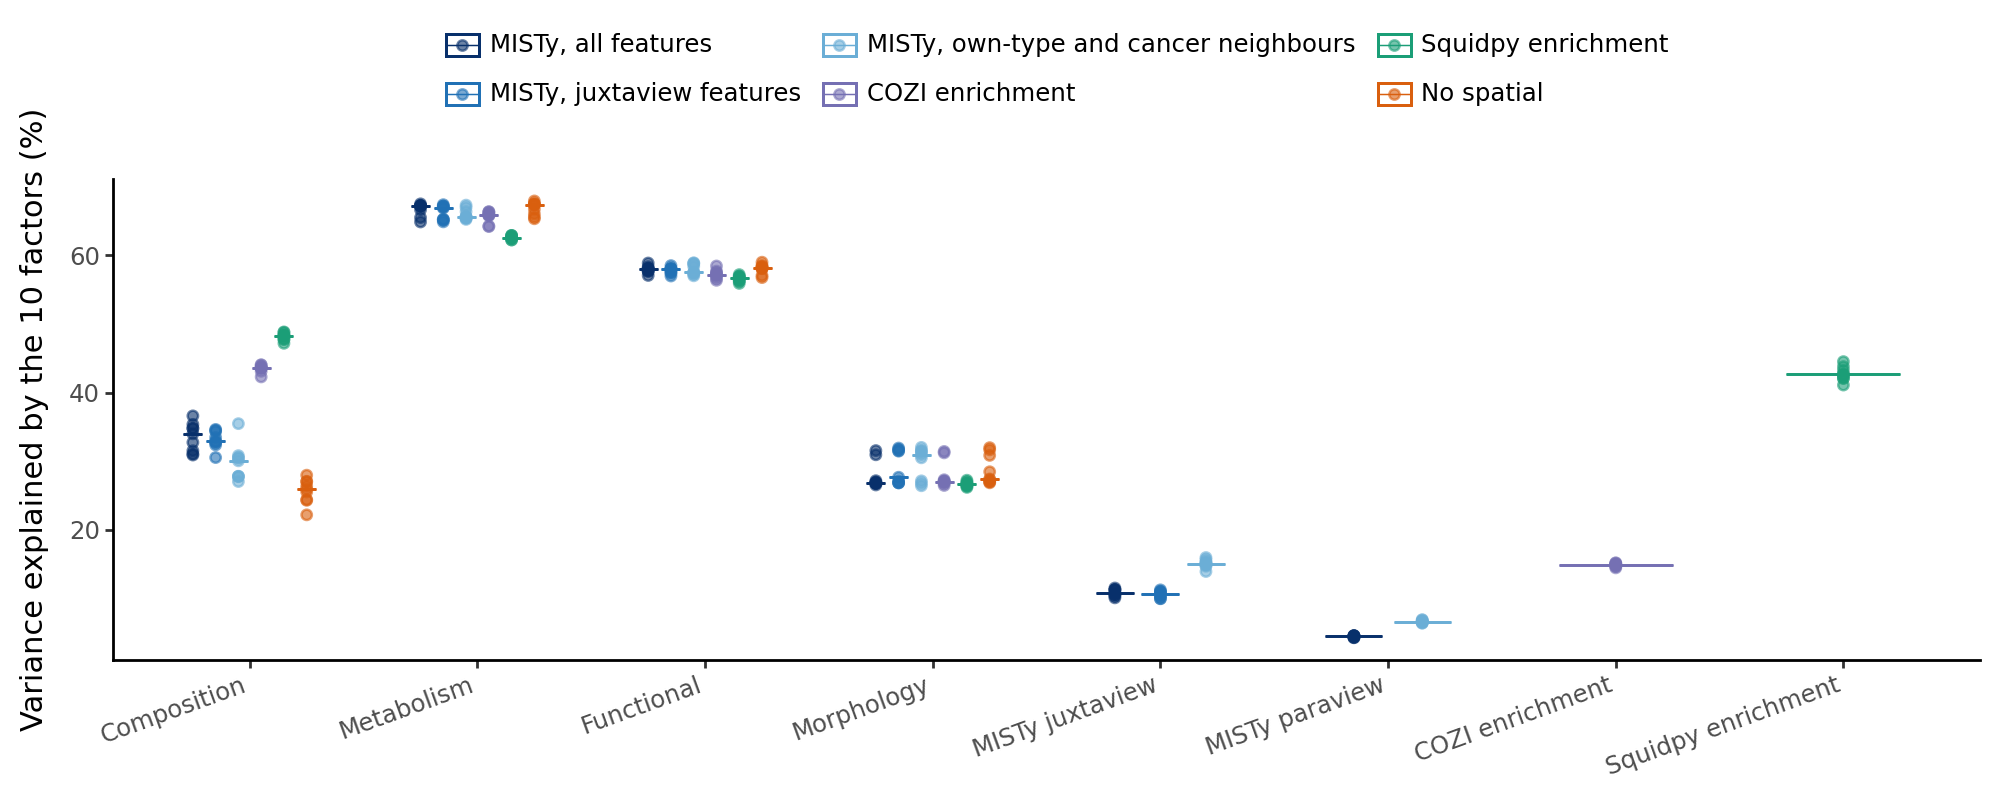

In [12]:
r2_all = pd.DataFrame([{"feature set": r["feature set"], "seed": r["seed"], **(r["r2 all factors"] * 100)} for r in refits])
r2_long = r2_all.melt(id_vars=["feature set", "seed"], var_name="class", value_name="r2").dropna()
r2_long["feature set"] = pd.Categorical(r2_long["feature set"], categories=list(feature_sets))
r2_long["class"] = pd.Categorical(r2_long["class"], categories=class_order)

gp = (ggplot(r2_long, aes(x="class", y="r2", color="feature set"))
      + geom_point(position=position_dodge(width=0.6), size=1.6, alpha=0.6)
      + stat_summary(fun_y=np.median, fun_ymin=np.median, fun_ymax=np.median, geom="crossbar",
                     position=position_dodge(width=0.6), width=0.5, size=0.3)
      + scale_color_manual(values=set_colors)
      + labs(x="", y="Variance explained by the 10 factors (%)", color="")
      + theme_classic()
      + theme(figure_size=(10, 4), legend_position="top", axis_text_x=element_text(rotation=20, ha="right")))
gp.save(figure_dir + "variance_explained_by_feature_set.pdf", verbose=False)
display(r2_all.groupby("feature set")[class_order].median().round(1).loc[list(feature_sets)])
gp

The squidpy z-scores are explained far better than the MISTy importances, and the COZI scores only somewhat better, as section 5 predicts. The composition class gains when either enrichment encoding enters, which fits the fact that composition predicts part of both, and most of squidpy.

### How far the factors move
Two fits on different feature sets have loadings on different features, so their factors can only be compared through the scores they give the 423 cores. For each factor of the reference model, two measures say how much of its scores a refit recovers:
- One matched factor: every reference factor is paired with a different refit factor, so that the squared correlations of the pairs add up to the largest possible total. The value is the squared correlation of a reference factor with its partner, which is the share of its variance that this one refit factor explains.
- All 10 factors: the reference factor is regressed on all 10 refit factors together. The value is the share of its variance that they explain.

Both values are shares of the variance of the same reference factor, so the second is never below the first. They differ when a refit finds the same variation between cores but spreads it differently over its factors. A reference factor then reappears as a mix of several refit factors, which only the second measure counts as recovered.

Both measures rest on the Pearson correlation, because MuVI is a linear model. The factor scores of a fit are close to a linear function of its scaled input, as the projection of new cores in `spatial/EncodingClinicalInformation.ipynb` shows. The scores of two fits are therefore related linearly, up to sign and scale, and the squared correlation measures that relation in full while ignoring sign and scale. A rank correlation would only lose precision.

The baseline comes from the set MISTy, all features. It is the published input, so its refits differ from the reference only by the seed.

Each point is one of the eight comparison seeds. The reference seed is left out, because its factors are the reference. The crossbar marks the median.

measure,One matched factor,All 10 factors
feature set,,
"MISTy, all features",0.389,0.966
"MISTy, juxtaview features",0.406,0.966
"MISTy, own-type and cancer neighbours",0.416,0.960
COZI enrichment,0.414,0.956
Squidpy enrichment,0.378,0.877
No spatial,0.408,0.972


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10
feature set,,,,,,,,,,
"MISTy, all features",0.76,0.99,0.98,0.94,0.99,0.95,0.99,0.85,0.95,0.98
"MISTy, juxtaview features",0.68,0.98,0.98,0.93,0.99,0.95,0.99,0.92,0.93,0.98
"MISTy, own-type and cancer neighbours",0.77,0.98,0.96,0.94,0.97,0.93,0.99,0.73,0.96,0.98
COZI enrichment,0.69,0.97,0.95,0.95,0.99,0.92,0.99,0.85,0.95,0.95
Squidpy enrichment,0.64,0.83,0.85,0.87,0.97,0.85,0.98,0.69,0.91,0.95
No spatial,0.67,0.98,0.97,0.97,0.99,0.95,0.99,0.72,0.95,0.97


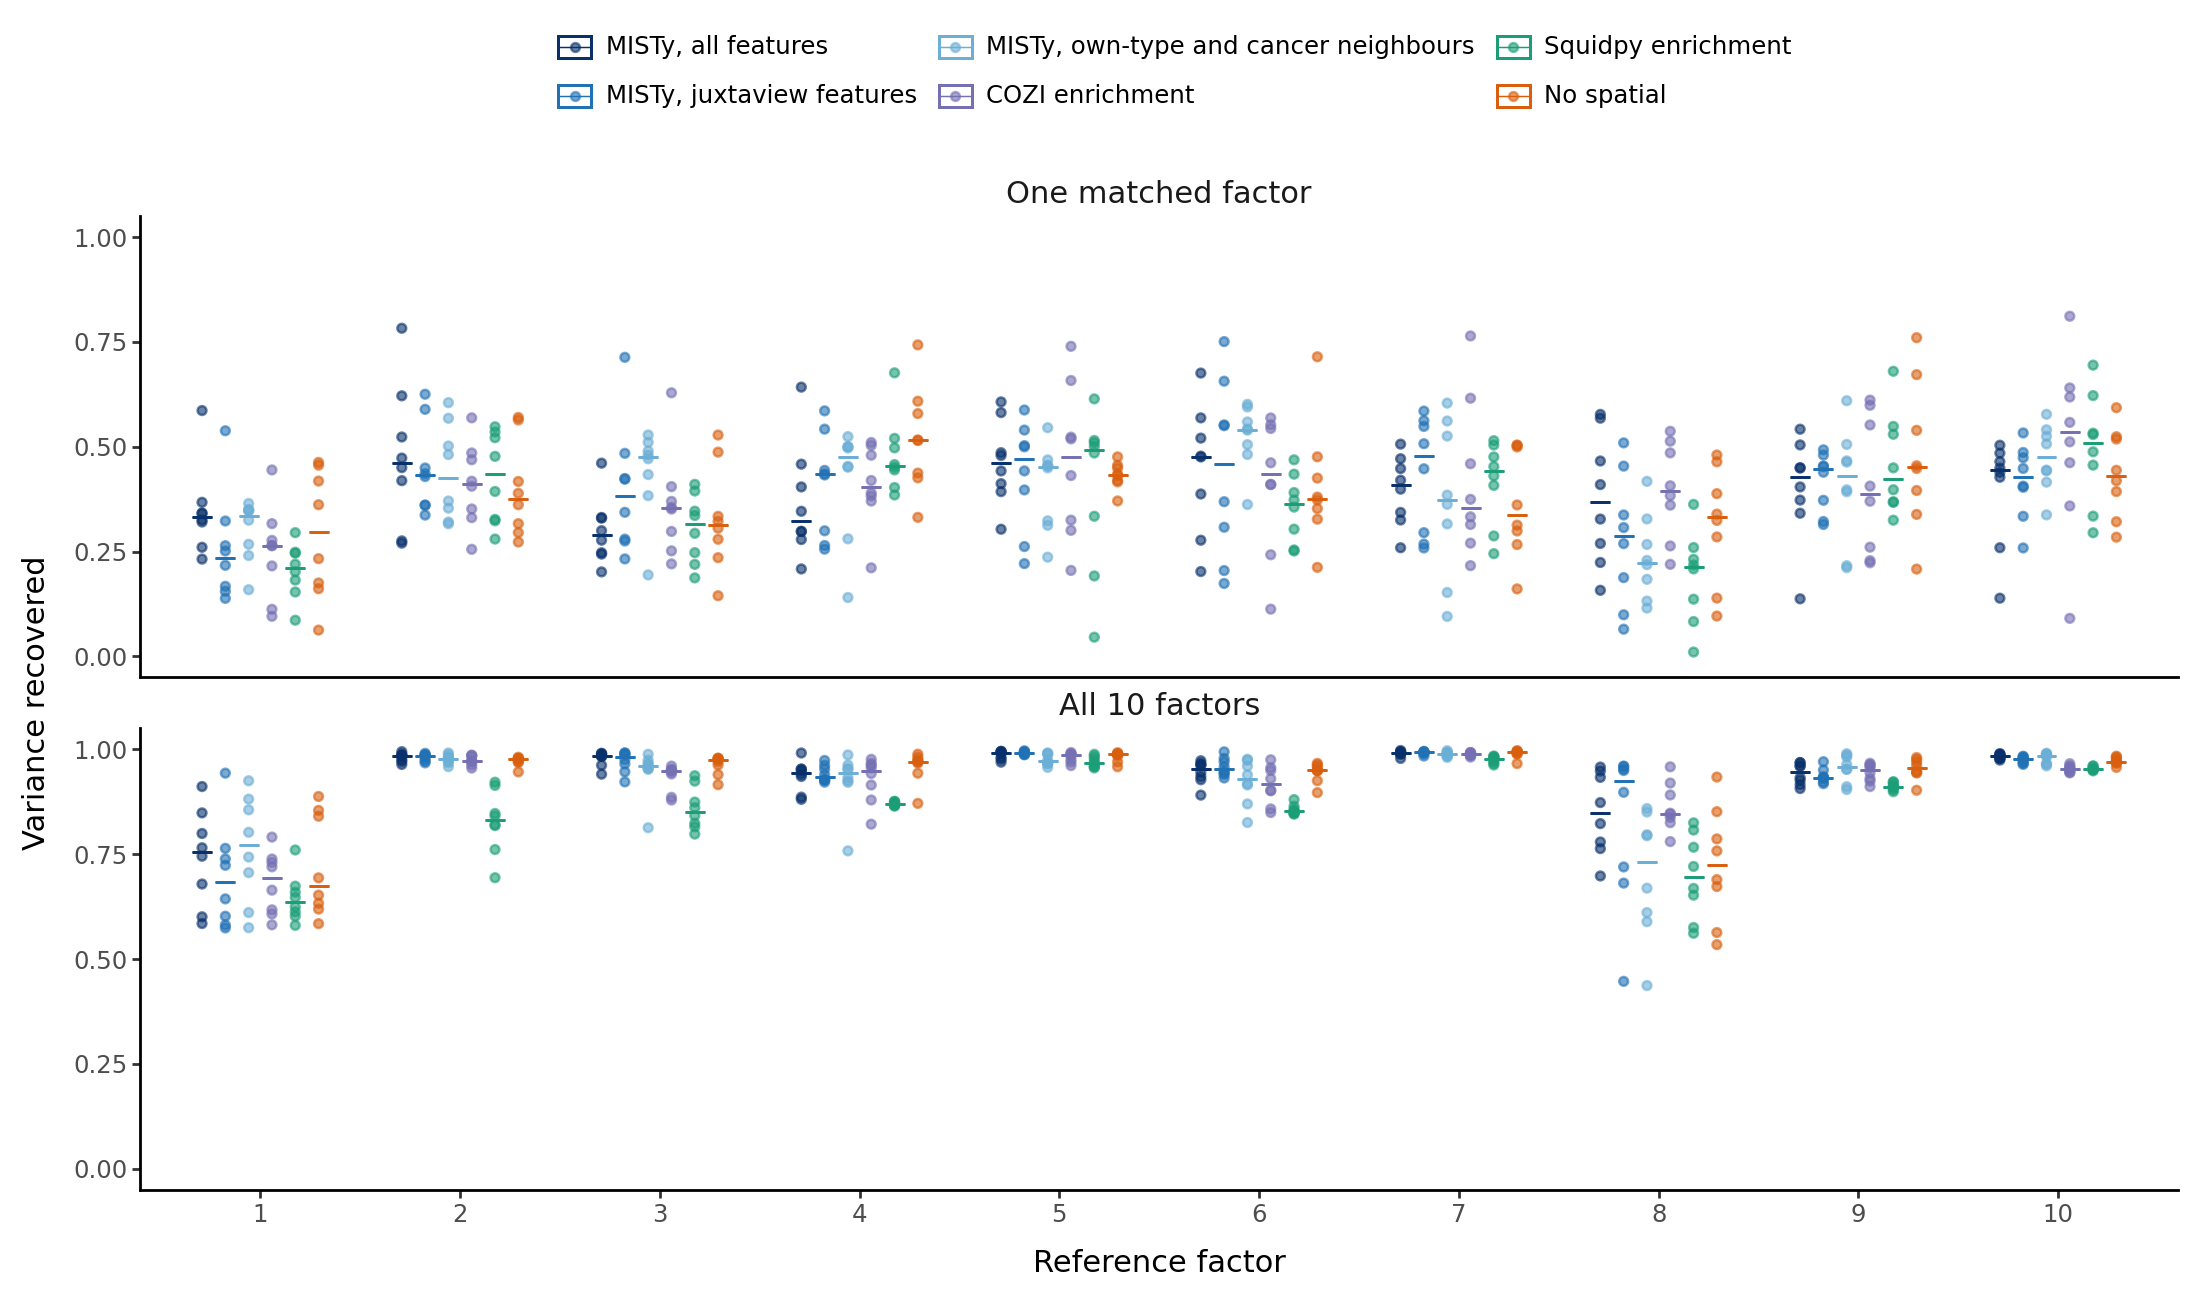

In [13]:
def matched_factor(scores):
    # Share of each reference factor's variance explained by its one-to-one matched refit factor
    squared = np.corrcoef(reference_scores.values.T, scores.values.T)[:n_factors, n_factors:] ** 2
    rows, columns = linear_sum_assignment(-squared)
    return pd.Series(squared[rows, columns], index=[factor_order[r] for r in rows])

def all_factors(scores):
    # Share of each reference factor's variance explained by all refit factors, by least squares
    design = np.column_stack([scores.values, np.ones(len(scores))])
    out = {}
    for factor in factor_order:
        y = reference_scores[factor].values
        residual = y - design @ np.linalg.lstsq(design, y, rcond=None)[0]
        out[factor] = 1 - (residual ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return pd.Series(out)

measures = {"One matched factor": matched_factor, "All 10 factors": all_factors}
recovery = pd.concat([
    pd.DataFrame([{"feature set": r["feature set"], "seed": r["seed"], "measure": name, **function(r["scores"])}
                  for r in refits if r["seed"] != reference_seed])
    for name, function in measures.items()])
recovery_long = recovery.melt(id_vars=["feature set", "seed", "measure"], var_name="factor", value_name="value")
recovery_long["feature set"] = pd.Categorical(recovery_long["feature set"], categories=list(feature_sets))
recovery_long["measure"] = pd.Categorical(recovery_long.measure, categories=list(measures))
recovery_long["factor"] = pd.Categorical(recovery_long.factor.str.replace("Factor ", ""),
                                         categories=[str(i) for i in range(1, 11)])

gp = (ggplot(recovery_long, aes(x="factor", y="value", color="feature set"))
      + geom_point(position=position_dodge(width=0.7), size=1.3, alpha=0.6)
      + stat_summary(fun_y=np.median, fun_ymin=np.median, fun_ymax=np.median, geom="crossbar",
                     position=position_dodge(width=0.7), width=0.6, size=0.3)
      + facet_wrap("~measure", ncol=1)
      + scale_color_manual(values=set_colors)
      + scale_y_continuous(limits=(0, 1))
      + labs(x="Reference factor", y="Variance recovered", color="")
      + theme_classic()
      + theme(figure_size=(11, 6.5), legend_position="top", strip_background=element_blank(),
              strip_text=element_text(size=11)))
gp.save(figure_dir + "factor_recovery.pdf", verbose=False)
display(recovery.assign(median=recovery[factor_order].median(axis=1))
        .pivot_table(index="feature set", columns="measure", values="median", aggfunc="median")
        .loc[list(feature_sets), list(measures)].round(3))
display(recovery[recovery.measure == "All 10 factors"].groupby("feature set")[factor_order].median()
        .loc[list(feature_sets)].round(2))
gp

A single matched refit factor recovers less than half of the variance of a reference factor, and this holds for the published input as much as for any other feature set. One numbered factor therefore does not come back from one seed to the next, and this measure cannot separate the feature sets.

All 10 refit factors together recover almost all of the variance of each reference factor on the published input. The refits find the same variation between cores but spread it differently over their factors. This is the baseline. The two MISTy subsets and the model without any spatial feature reach it, so the factors do not depend on the MISTy importances. COZI stays close to it. Squidpy falls clearly below it, mostly for Factors 2, 3, 4 and 6, which include the two factors of the second reviewer comment. Factor 1 is the least stable factor in every feature set, the published input included, and Factor 8 varies most between feature sets.

## 7. Do the enrichment encodings make the factors more spatial?
Moving the factors is not the same as making them more spatial. An enrichment z-score is built from the counts of each cell type around each cell, so cell type composition predicts part of it, and a factor that captures composition will also predict that part. A fair test removes composition first.

The test takes each spatial encoding in turn as the target, and asks how well the 10 factor scores of each model predict it, by ridge regression with five-fold cross-validation, in two versions:
- As measured: the target encoding as it is.
- After removing composition: the part of the encoding that composition does not predict. Composition here is the fraction of each annotated cell type in the core, plus the log of the number of cells, which sets how much power an enrichment score has. The residual is taken out of fold, so composition never sees the cores it is subtracted from.

A model whose factors carry spatial information should predict the composition-free part of another encoding better than the model without any spatial feature does. Where a model was fit on the target encoding itself, recovering it shows only that the model kept its own input.

In the heatmap, each cell is the median over the nine seeds, and an asterisk marks a model fit on at least part of the target encoding.

In [14]:
cell_types_per_core = pd.read_csv(data_dir + "cell_table_with_types_stage.csv", usecols=["fov", "annotation_consensus"])
cell_types_per_core = cell_types_per_core[cell_types_per_core.fov.isin(features.obs_names)]
composition = pd.crosstab(cell_types_per_core.fov, cell_types_per_core.annotation_consensus,
                          normalize="index").reindex(features.obs_names)
composition["log cell count"] = np.log(cell_types_per_core.groupby("fov").size().reindex(features.obs_names))
composition_matrix = zero_filled(composition)

def out_of_fold_residual(predictors, targets):
    '''What the predictors fail to predict, each core predicted by a model that did not see it'''
    residual = np.zeros_like(targets)
    for train, test in KFold(5, shuffle=True, random_state=split_seed).split(predictors):
        fitted = RidgeCV(alphas=ridge_alphas).fit(predictors[train], targets[train])
        residual[test] = targets[test] - fitted.predict(predictors[test])
    return residual

targets = ["MISTy, all features", "COZI enrichment", "Squidpy enrichment"]
fit_on = {"MISTy, all features": ["MISTy, all features", "MISTy, juxtaview features", "MISTy, own-type and cancer neighbours"],
          "COZI enrichment": ["COZI enrichment"], "Squidpy enrichment": ["Squidpy enrichment"]}
blocks = {label: zero_filled(spatial_block(feature_sets[label])) for label in targets}
composition_free = {name: out_of_fold_residual(composition_matrix, block) for name, block in blocks.items()}

pd.Series({name: cross_validated_r2(composition_matrix, block) for name, block in blocks.items()},
          name="share predicted by composition alone").round(3).to_frame()

,share predicted by composition alone
"MISTy, all features",0.052
COZI enrichment,0.120
Squidpy enrichment,0.275


In [15]:
prediction = []
for r in refits:
    factors = r["scores"].values
    for name in blocks:
        for version, target in [("As measured", blocks[name]), ("After removing composition", composition_free[name])]:
            prediction.append({"feature set": r["feature set"], "seed": r["seed"], "target encoding": name,
                               "version": version, "r2": cross_validated_r2(factors, target)})
prediction = pd.DataFrame(prediction)
prediction_table = (prediction.groupby(["version", "feature set", "target encoding"]).r2.median()
                    .unstack("target encoding")[list(blocks)])
prediction_table.round(3)

target encoding                                                   MISTy, all features  \
version                    feature set                                                  
After removing composition COZI enrichment                                      0.003   
                           MISTy, all features                                  0.005   
                           MISTy, juxtaview features                            0.004   
                           MISTy, own-type and cancer neighbours                0.003   
                           No spatial                                           0.002   
                           Squidpy enrichment                                   0.005   
As measured                COZI enrichment                                      0.031   
                           MISTy, all features                                  0.033   
                           MISTy, juxtaview features                            0.031   
                           MISTy, own-type and cancer neighbours                0.027   
                           No spatial                                           0.021   
                           Squidpy enrichment                                   0.043   

target encoding                                                   COZI enrichment  \
version                    feature set                                              
After removing composition COZI enrichment                                  0.004   
                           MISTy, all features                              0.001   
                           MISTy, juxtaview features                        0.001   
                           MISTy, own-type and cancer neighbours            0.000   
                           No spatial                                       0.000   
                           Squidpy enrichment                               0.008   
As measured                COZI enrichment                                  0.094   
                           MISTy, all features                              0.047   
                           MISTy, juxtaview features                        0.045   
                           MISTy, own-type and cancer neighbours            0.037   
                           No spatial                                       0.032   
                           Squidpy enrichment                               0.118   

target encoding                                                   Squidpy enrichment  
version                    feature set                                                
After removing composition COZI enrichment                                     0.021  
                           MISTy, all features                                 0.015  
                           MISTy, juxtaview features                           0.014  
                           MISTy, own-type and cancer neighbours               0.011  
                           No spatial                                          0.012  
                           Squidpy enrichment                                  0.100  
As measured                COZI enrichment                                     0.192  
                           MISTy, all features                                 0.103  
                           MISTy, juxtaview features                           0.103  
                           MISTy, own-type and cancer neighbours               0.088  
                           No spatial                                          0.076  
                           Squidpy enrichment                                  0.361

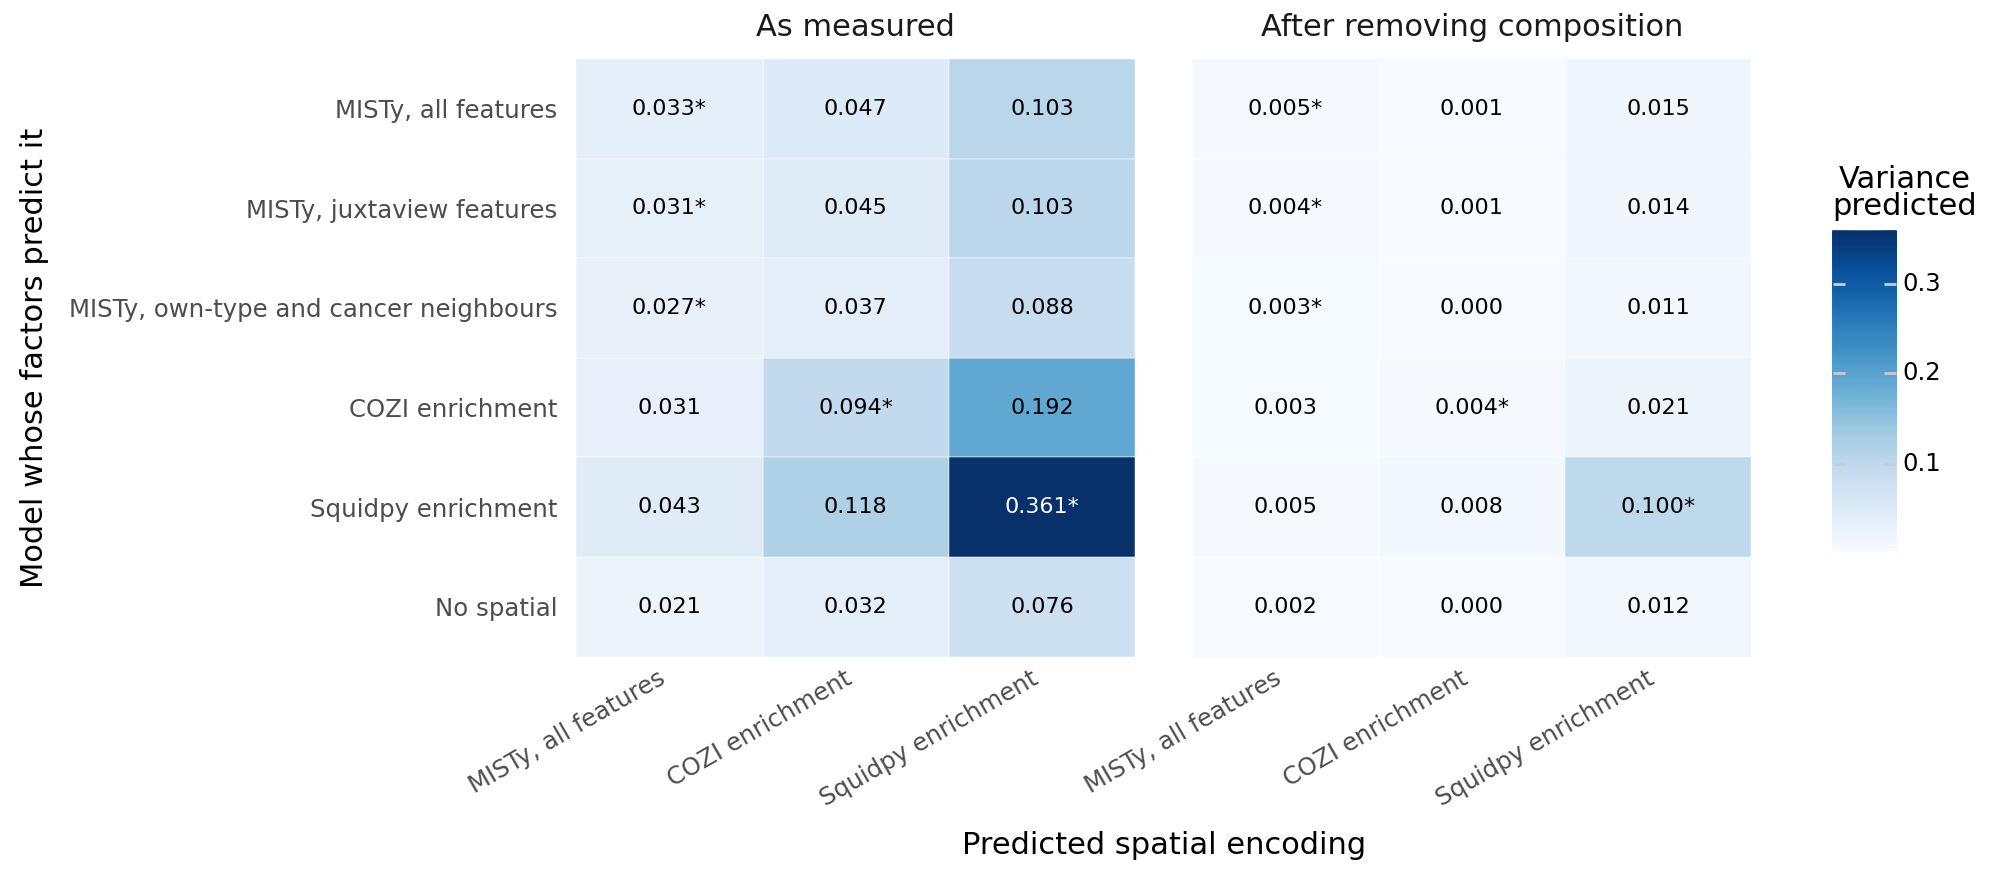

In [16]:
heat = prediction.groupby(["version", "feature set", "target encoding"]).r2.median().reset_index()
heat["own input"] = [row["feature set"] in fit_on[row["target encoding"]] for _, row in heat.iterrows()]
heat["label"] = heat.r2.map("{:.3f}".format) + np.where(heat["own input"], "*", "")
heat["feature set"] = pd.Categorical(heat["feature set"], categories=list(feature_sets)[::-1])
heat["target encoding"] = pd.Categorical(heat["target encoding"], categories=list(blocks))
heat["version"] = pd.Categorical(heat.version, categories=["As measured", "After removing composition"])

gp = (ggplot(heat, aes(x="target encoding", y="feature set", fill="r2"))
      + geom_tile(color="white")
      + geom_text(aes(label="label", color="r2 > 0.25"), size=8, show_legend=False)
      + scale_color_manual(values={True: "white", False: "black"})
      + facet_wrap("~version", ncol=2)
      + scale_fill_r2("Variance\npredicted")
      + labs(x="Predicted spatial encoding", y="Model whose factors predict it")
      + theme_classic()
      + theme(figure_size=(10, 4.4), axis_line=element_blank(), axis_ticks=element_blank(),
              axis_text_x=element_text(rotation=30, ha="right"),
              strip_background=element_blank(), strip_text=element_text(size=11)))
gp.save(figure_dir + "spatial_encoding_prediction.pdf", verbose=False)
gp

In the left panel, the factors of every model predict the enrichment encodings to some degree, even those of the model without any spatial feature. Composition explains this. It predicts part of both enrichment encodings, most of all of squidpy, and every model captures composition.

The right panel removes composition. The factors of every model then predict almost nothing of the encodings they were not fit on. The differences from the model without any spatial feature are a small fraction of an already small value. The only cell that stands out is the squidpy model predicting the squidpy scores, which is that model keeping its own input. The enrichment encodings compress better, but the factors they produce carry no more spatial information than factors fit without any spatial feature.

## 8. Summary
The table gathers the numbers the conclusions rest on.

In [17]:
def spatial_explained(label):
    '''Variance of the whole spatial block explained by the 10 factors. Every feature has unit variance,
    so the spatial classes of a set combine in proportion to their number of features.'''
    sizes = spatial_block(feature_sets[label]).columns.map(feature_class).value_counts()
    if sizes.empty:
        return np.nan
    medians = r2_all[r2_all["feature set"] == label][sizes.index].median()
    return float((medians * sizes).sum() / sizes.sum())

all_factor_median = (recovery[recovery.measure == "All 10 factors"]
                   .assign(median=lambda d: d[factor_order].median(axis=1)).groupby("feature set")["median"].median())
summary = pd.DataFrame({
    "spatial features": {label: spatial_block(views).shape[1] for label, views in feature_sets.items()},
    "spatial variance explained (%)": {label: spatial_explained(label) for label in feature_sets},
    "variance recovered by all 10 factors": all_factor_median,
}).loc[list(feature_sets)]
summary = summary.join(properties[["Predictable from the other classes", "Reach of 10 components"]])
summary.round(3)

,spatial features,spatial variance explained (%),variance recovered by all 10 factors,Predictable from the other classes,Reach of 10 components
"MISTy, all features",100,7.195,0.966,0.028,0.251
"MISTy, juxtaview features",43,10.673,0.966,0.074,0.423
"MISTy, own-type and cancer neighbours",31,10.422,0.960,0.073,0.529
COZI enrichment,64,14.879,0.956,0.078,0.425
Squidpy enrichment,64,42.668,0.877,0.224,0.680
No spatial,0,NaN,0.972,NaN,NaN


The published factors explain only a small part of the spatial features. Metabolism, the functional markers and composition drive them, as the reviewer reads Factors 2 and 6. This is a technical property of the input more than a biological one. MISTy encodes space as sparse importances that barely correlate with each other or with the other classes. A factor model explains a feature only through its covariances with other features, as section 9 shows, so a model with 10 factors explains these importances poorly, and removing them leaves the factors in place.

Squidpy neighbourhood enrichment, a denser encoding of the same cell positions whose features correlate, compresses much better and moves the factors. A large part of what it adds, though, is cell type composition. COZI enrichment is just as dense, but its features correlate little, and the factors keep little more of it than of the MISTy importances. After composition is removed, their factors carry no more spatial information than factors fit without any spatial feature. Better compression of a spatial encoding does not make the factors more spatial.

A multifactorial design built for this question could go further. It could weight the feature classes, or model the spatial features in views of their own so that the other classes cannot absorb the factors. That is beyond this notebook.

A caveat applies to every factor-level statement. A single factor does not come back from one seed to the next, while the 10 factors together do. The content of one numbered factor is therefore a property of the retained model, and the same holds for the clinical associations reported elsewhere.

## 9. Why the factors leave uncorrelated features unexplained
The results above follow from the form of the model. MuVI models the scaled feature $j$ of core $i$ as

$$x_{ij} = z_i W_j + e_{ij}, \qquad z_i \sim \mathcal{N}(0, I), \qquad e_{ij} \sim \mathcal{N}(0, \sigma_j^2),$$

where $z_i$ holds the 10 factor scores of the core, $W_j$ the loadings of feature $j$ on the 10 factors, and $\sigma_j^2$ the noise variance of the feature. Averaged over the factor scores, the model implies a covariance between features:

$$\operatorname{Var}(x_j) = \lVert W_j \rVert^2 + \sigma_j^2 = 1, \qquad \operatorname{Cov}(x_j, x_l) = W_j^\top W_l \quad \text{for } j \neq l.$$

The share of feature $j$ that the factors explain is $R^2_j = \lVert W_j \rVert^2$.

Only the covariances between features drive the loadings. With the factor scores averaged out, the Gaussian likelihood of $n$ cores depends on the parameters only through $\Sigma = W^\top W + \operatorname{diag}(\sigma^2)$, and on the data only through the sample covariance $S$:

$$\log L = -\tfrac{n}{2}\left[\log\det\Sigma + \operatorname{tr}(\Sigma^{-1}S)\right] + \text{constant}.$$

MuVI keeps the factor scores explicit and fits them by variational inference, but it targets the same likelihood. Any split of a feature's unit variance between $\lVert W_j\rVert^2$ and $\sigma_j^2$ fits the diagonal of $S$ equally well. A feature's own variance therefore gives the model no reason to explain it. Only its covariances with other features have to come from the loadings. Two consequences follow.

A feature uncorrelated with every other feature gets no variance explained. The fit needs $W_j^\top W_l = 0$ for every other feature $l$. Unless a factor loads feature $j$ alone, the loadings of the other features span all 10 factor directions, so $W_j = 0$ and $R^2_j = 0$. A factor that loads feature $j$ alone leaves the likelihood unchanged, since it only moves variance from $\sigma_j^2$ to $\lVert W_j\rVert^2$. With 10 factors for a few hundred features, every factor gains more by reproducing covariance that many features share. The priors on the factor scores and on the loadings penalise loadings that do not improve the likelihood, so they push the same way.

A correlated feature gets a minimum. By the Cauchy-Schwarz inequality,

$$|\operatorname{corr}(x_j, x_l)| = |W_j^\top W_l| \le \lVert W_j\rVert\,\lVert W_l\rVert \le \sqrt{R^2_j}, \qquad \text{so} \qquad R^2_j \ge \max_{l \neq j} \operatorname{corr}(x_j, x_l)^2.$$

With 10 factors, the model reproduces the covariances only approximately, so the bound holds approximately too.

Sparsity does not enter the model. The Gaussian likelihood sees only means and covariances, and a sparse feature that varies together with others would be explained as well as a dense one. Sparsity matters because it lowers correlations. Two features that are mostly zero, and nonzero in different cores, barely correlate. It also makes Gaussian noise a poor description of the feature, which raises $\sigma_j^2$ without creating shared covariance.

The mean absolute correlation of section 5 can be set against chance. Two independent features measured on $n$ cores correlate by chance with a mean absolute value of about $\sqrt{2/(\pi n)}$.

In [18]:
n_cores = len(features.obs_names)
chance = np.sqrt(2 / (np.pi * n_cores))
print(f"mean absolute correlation of two independent features over {n_cores} cores: about {chance:.3f}")
properties[["Mean absolute correlation"]].assign(
    **{"multiple of chance": properties["Mean absolute correlation"] / chance}).round(3)

mean absolute correlation of two independent features over 423 cores: about 0.039


,Mean absolute correlation,multiple of chance
feature set,,
"MISTy, all features",0.051,1.325
"MISTy, juxtaview features",0.069,1.777
"MISTy, own-type and cancer neighbours",0.071,1.833
COZI enrichment,0.079,2.044
Squidpy enrichment,0.201,5.182


The MISTy importances and the COZI scores correlate only slightly above chance, and far less than the squidpy z-scores. The form of the model therefore predicts what sections 3 to 6 observe. The factors explain little of the MISTy importances and of the COZI scores, and much more of the squidpy z-scores, whose features correlate with each other and with the other classes. The COZI scores show that density alone does not help. They have no exact zeros, yet the factors explain little more of them than of the MISTy subsets. The exact zeros of section 5 explain why the MISTy importances correlate so little, but they are not a separate cause.

## Export

In [19]:
reference_r2.to_csv(output_dir + "reference_variance_explained_by_class.csv")
share.to_csv(output_dir + "reference_loading_share_by_class.csv")
properties.to_csv(output_dir + "spatial_encoding_properties.csv")
r2_all.to_csv(output_dir + "variance_explained_by_feature_set.csv", index=False)
recovery.to_csv(output_dir + "factor_recovery.csv", index=False)
prediction.to_csv(output_dir + "spatial_encoding_prediction.csv", index=False)
summary.to_csv(output_dir + "summary.csv")
feature_table.to_csv(output_dir + "feature_classes.csv", index=False)